# 🌱 Lesson 3: Data Transformation: Scaling, Log Transforms & Encoding
**Phase 2 · Data Preprocessing & Feature Engineering** &nbsp;|&nbsp; ⏱ about 3 hours &nbsp;|&nbsp; 📚 Prerequisite: Lesson 02 (uses the cleaned dataset it saved)

> *A model speaks in numbers. Our job is to translate, without changing the meaning.*

## 🎯 By the end of this lesson you will be able to
- Explain *why* some models need scaled inputs and others don't.
- Apply min-max normalisation, standardisation and robust scaling, and choose between them.
- Reduce skew with log, square-root and power transforms.
- Encode nominal (one-hot) and ordinal categories correctly, and avoid the classic traps.
- Use `fit` on training data and `transform` on everything else.

---

In [1]:
import sys
sys.path.append("../utils")            # lets us import course_utils.py and agri_prep.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from course_utils import *             # load_raw_farm, profile, setup_plots, ...

setup_plots()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
np.random.seed(42)

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import (MinMaxScaler, StandardScaler, RobustScaler, PowerTransformer,
                                   QuantileTransformer, OneHotEncoder, OrdinalEncoder)

df = load_lesson_clean()           # created at the end of Lesson 02
print(df.shape)
df.head(3)

(2329, 22)


,farm_id,county,soil_type,farm_size_ha,experience,crop,season,planting_date,harvest_date,rainfall_mm,avg_temp_c,soil_ph,nitrogen_ppm,phosphorus_ppm,potassium_ppm,organic_matter_pct,fertilizer_kg_ha,irrigation,pest_pressure,market_price_ksh_kg,total_revenue_ksh,yield_t_ha
0,F0431,Machakos,Clay,1.06,Advanced,Potato,Long rains,2023-04-06,2023-07-18,491.1,21.7,6.61,27.6,11.0,226.4,1.90,66.0,1,High,43.8,174105.0,3.75
1,F0466,Kakamega,Clay,0.77,Advanced,Sorghum,Short rains,2021-11-09,2022-03-13,645.8,19.6,5.83,17.4,18.5,134.6,2.68,NaN,1,Medium,53.0,6530.0,0.16
2,F0534,Kisii,Volcanic,1.69,Intermediate,Potato,Long rains,2019-03-16,2019-07-02,905.6,16.6,5.58,18.6,13.4,101.3,2.55,69.0,1,Low,31.8,204220.0,3.80


# Part 1 · Why do we scale?

## 1.1 The problem: features live on different scales
Rainfall is measured in **hundreds** (≈ 650 mm). Soil pH lives between **3 and 10**. Any algorithm that uses *distances* or *gradients* will let the big-number feature shout over the small-number one.

### A thought experiment with three farms
Which farm is most *similar* to Farm A?

In [3]:
cols = ["rainfall_mm", "soil_ph"]
farms = pd.DataFrame({"rainfall_mm": [600, 650, 900], "soil_ph": [5.0, 7.0, 5.2]}, index=["A", "B", "C"])
print(farms, "\n")

def dist(table, a, b):
    return float(np.sqrt(((table.loc[a] - table.loc[b]) ** 2).sum()))

print("UNSCALED distances    A–B: %.1f   A–C: %.1f   → B looks far closer" % (dist(farms, "A", "B"), dist(farms, "A", "C")))

scaled = (farms - df[cols].mean()) / df[cols].std()          # use typical spread of each feature
print("SCALED   distances    A–B: %.2f   A–C: %.2f   → now C is closer" % (dist(scaled, "A", "B"), dist(scaled, "A", "C")))

   rainfall_mm  soil_ph
A          600      5.0
B          650      7.0
C          900      5.2 

UNSCALED distances    A–B: 50.0   A–C: 300.0   → B looks far closer
SCALED   distances    A–B: 3.45   A–C: 1.68   → now C is closer


Unscaled, the 50 mm rainfall gap between A and B swamps everything, and the pH difference of **2 whole units** (a huge agronomic difference; acidic vs neutral soil) is invisible. After scaling, each feature is measured in *"typical-spread units"* and pH finally gets a voice.

## 1.2 Does it matter on real data? An experiment
We'll predict **maize yield** from numeric conditions using k-Nearest Neighbours (a distance-based model) and a Random Forest (a tree model), with and without scaling.

> Notice the right way to do it: **split first**, `fit` the scaler on the *training* rows only, `transform` both.

In [4]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor

feats = ["rainfall_mm", "avg_temp_c", "soil_ph", "nitrogen_ppm", "organic_matter_pct", "farm_size_ha"]
maize = df[df["crop"] == "Maize"].dropna(subset=feats)
X_tr, X_te, y_tr, y_te = train_test_split(maize[feats], maize["yield_t_ha"], test_size=0.25, random_state=0)

scaler = StandardScaler().fit(X_tr)                                    # LEARN mean/std from TRAIN only
Xs_tr, Xs_te = scaler.transform(X_tr), scaler.transform(X_te)          # APPLY to both

res = {}
for name, model in {"KNN": KNeighborsRegressor(15), "Random Forest": RandomForestRegressor(200, random_state=0, n_jobs=-1)}.items():
    res[name] = {"R² unscaled": model.fit(X_tr, y_tr).score(X_te, y_te),
                 "R² scaled":   model.fit(Xs_tr, y_tr).score(Xs_te, y_te)}
pd.DataFrame(res).T.round(3)

,R² unscaled,R² scaled
KNN,-0.011,0.543
Random Forest,0.616,0.618


Scaling changes the **KNN** result noticeably, while the **Random Forest** doesn't care (its splits only compare values *within* one feature). Rule of thumb:

| Needs scaling | Doesn't need scaling |
|---|---|
| KNN, K-Means, SVM, neural networks, PCA, logistic/linear regression (esp. regularised), gradient-descent anything | Decision trees, Random Forest, Gradient Boosting (XGBoost, LightGBM) |

When unsure: **scale**. It rarely hurts and often helps.

---
# Part 2 · Normalisation (min-max scaling)

$$x' = \frac{x - x_{min}}{x_{max} - x_{min}}$$

Squeezes values into **[0, 1]**: the smallest becomes 0, the largest 1. By hand:

In [5]:
x = np.array([420, 560, 640, 700, 810, 900], dtype=float)         # six rainfall values
manual = (x - x.min()) / (x.max() - x.min())
print("manual :", manual.round(3))

mm = MinMaxScaler().fit(x.reshape(-1, 1))                         # sklearn wants 2-D: (rows, features)
print("sklearn:", mm.transform(x.reshape(-1, 1)).ravel().round(3))
print("learned: data_min_ =", mm.data_min_, "| data_max_ =", mm.data_max_)

manual : [0.    0.292 0.458 0.583 0.812 1.   ]
sklearn: [0.    0.292 0.458 0.583 0.812 1.   ]
learned: data_min_ = [420.] | data_max_ = [900.]


`fit` **learned two numbers** (min and max). `transform` applied them. Nothing else. Now the crucial behaviours:

**(1) New data can fall outside [0, 1]**: and that's correct:

In [6]:
print("train range [0, 10] → new value 15 maps to:", MinMaxScaler().fit([[0], [10]]).transform([[15]]).ravel())

train range [0, 10] → new value 15 maps to: [1.5]


**(2) Outliers wreck it.** The scale is defined by the *extremes*. One giant farm and everyone else is squashed against 0:

largest farm: 378 ha
99.4% of all farms are squeezed into the scaled range 0 – 0.05


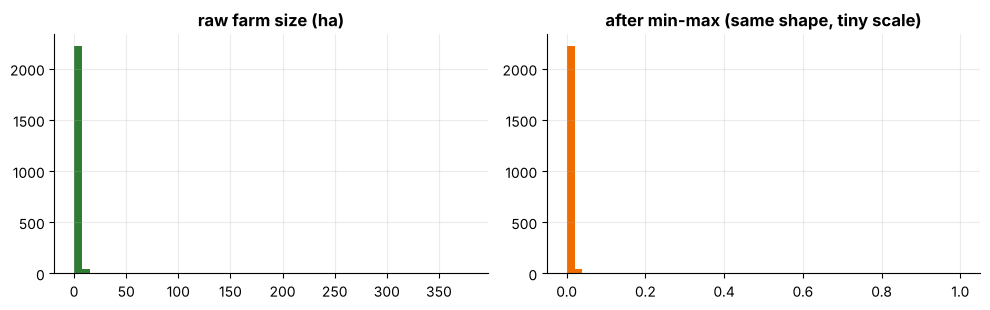

In [7]:
size = df[["farm_size_ha"]].dropna()
mm_size = MinMaxScaler().fit_transform(size).ravel()
print(f"largest farm: {size['farm_size_ha'].max():.0f} ha")
print(f"{(mm_size < 0.05).mean() * 100:.1f}% of all farms are squeezed into the scaled range 0 – 0.05")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(size["farm_size_ha"], bins=50); ax[0].set_title("raw farm size (ha)")
ax[1].hist(mm_size, bins=50, color="#EF6C00"); ax[1].set_title("after min-max (same shape, tiny scale)")
plt.tight_layout(); plt.show()

> 🧠 **Pause and predict:** If we remove the outlier farms *first*, will min-max become useful for this column?
> <details><summary>Answer</summary>Much more useful (but then we're doing outlier treatment (Lesson 2) *and* scaling, and any cap we use must be learned from training data only. Alternatively use a scaler that doesn't care about extremes) coming up next.</details>

**Use min-max when:** you need a bounded range (e.g. neural networks, image pixels), data has no big outliers, or the algorithm assumes [0,1].

---
# Part 3 · Standardisation (z-score scaling)

$$z = \frac{x - \mu}{\sigma}$$

Centres at **mean 0** and spreads to **standard deviation 1**. No fixed range, so outliers don't compress everyone else (they just get a big z).

In [8]:
train, test = train_test_split(df.dropna(subset=["rainfall_mm"]), test_size=0.2, random_state=0)

ss = StandardScaler().fit(train[["rainfall_mm"]])
print(f"learned: mean_ = {ss.mean_[0]:.1f}   scale_ (std) = {ss.scale_[0]:.1f}\n")

z_train = ss.transform(train[["rainfall_mm"]]).ravel()
z_test  = ss.transform(test[["rainfall_mm"]]).ravel()
print(f"train → mean {z_train.mean():+.3f}, std {z_train.std():.3f}   (exactly 0 and 1, by construction)")
print(f"test  → mean {z_test.mean():+.3f}, std {z_test.std():.3f}   (close, but NOT exactly 0 and 1, and it should not be!)")

learned: mean_ = 663.5   scale_ (std) = 183.3

train → mean +0.000, std 1.000   (exactly 0 and 1, by construction)
test  → mean -0.080, std 0.974   (close, but NOT exactly 0 and 1, and it should not be!)


The test set is *not* exactly mean-0/std-1, and **that's correct**. We deliberately use the training statistics so the model sees the test data through exactly the same lens it was trained with, as it would see tomorrow's new data. (If you re-fit on the test set, you've leaked; Lesson 6.)

## Robust scaling
For skewed or outlier-heavy columns use the **median** and **IQR** instead of mean and std: $x' = (x - \text{median}) / \text{IQR}$.

In [9]:
s = df[["farm_size_ha"]].dropna()
table = {}
for name, sc in [("raw", None), ("MinMax", MinMaxScaler()), ("Standard", StandardScaler()), ("Robust", RobustScaler())]:
    v = s["farm_size_ha"].to_numpy() if sc is None else sc.fit_transform(s).ravel()
    table[name] = {"min": v.min(), "5th pct": np.percentile(v, 5), "median": np.median(v),
                   "95th pct": np.percentile(v, 95), "max": v.max(), "skew": pd.Series(v).skew()}
pd.DataFrame(table).T.round(2)

,min,5th pct,median,95th pct,max,skew
raw,0.10,0.24,1.07,4.98,377.70,14.36
MinMax,0.00,0.00,0.00,0.01,1.00,14.36
Standard,-0.15,-0.15,-0.10,0.11,20.19,14.36
Robust,-0.71,-0.61,0.00,2.86,275.41,14.36


Study the **skew** column: *every scaler leaves skewness exactly unchanged* (the same number in every row. Scaling is a **linear** change) it relabels the axis but cannot change the **shape**. Only non-linear transforms (next section) can. And look at Robust: the middle 90% of farms live comfortably around −0.5 … +2, while MinMax squeezes them near 0.

| Scaler | Formula | Best for | Watch out |
|---|---|---|---|
| **MinMax** | (x−min)/(max−min) | Bounded inputs, no outliers | Outliers squash everything |
| **Standard** | (x−mean)/std | Most models; roughly symmetric data | Mean/std affected by outliers |
| **Robust** | (x−median)/IQR | Outliers present | Unbounded range |

---
# Part 4 · Skewed data and log transformations

## 4.1 Which features are skewed?
Skewness: 0 = symmetric; > 1 = strongly right-skewed (long tail of large values); < −1 = left-skewed.

In [10]:
skew = df.select_dtypes("number").skew().sort_values(ascending=False)
skew.round(2).to_frame("skewness").T

,farm_size_ha,nitrogen_ppm,total_revenue_ksh,yield_t_ha,phosphorus_ppm,market_price_ksh_kg,irrigation,avg_temp_c,fertilizer_kg_ha,soil_ph,potassium_ppm,organic_matter_pct,rainfall_mm
skewness,14.36,7.68,4.76,2.35,1.52,1.29,1.22,0.2,0.13,0.06,-0.03,-0.04,-0.13


`farm_size_ha`, `nitrogen_ppm` (a few extreme lab readings) and `total_revenue_ksh` (money!) are heavily right-skewed. Money, sizes, populations and counts typically are: they grow **multiplicatively**. 10% of a small farm is small; 10% of a large farm is large.

## 4.2 Why log helps
Logarithms turn *multiplication into addition*: `log(a × b) = log(a) + log(b)`. A farm 10× bigger sits one "step" to the right, no matter where you start: the long tail gets pulled in.

In [11]:
x = np.array([1, 10, 100, 1000, 10000])
print("x      :", x)
print("log10  :", np.log10(x))
print("log1p  :", np.log1p(x).round(2), "  # log(1+x): safe even when x = 0")

x      : [    1    10   100  1000 10000]
log10  : [0. 1. 2. 3. 4.]
log1p  : [0.69 2.4  4.62 6.91 9.21]   # log(1+x): safe even when x = 0


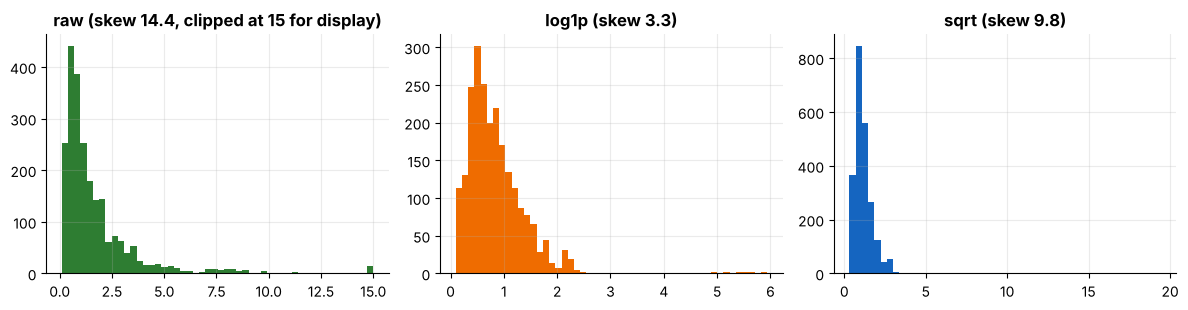

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
s = df["farm_size_ha"].dropna()
ax[0].hist(s.clip(upper=15), bins=50); ax[0].set_title(f"raw (skew {s.skew():.1f}, clipped at 15 for display)")
ax[1].hist(np.log1p(s), bins=50, color="#EF6C00"); ax[1].set_title(f"log1p (skew {np.log1p(s).skew():.1f})")
ax[2].hist(np.sqrt(s), bins=50, color="#1565C0"); ax[2].set_title(f"sqrt (skew {np.sqrt(s).skew():.1f})")
plt.tight_layout(); plt.show()

After `log1p` the *bulk* of the farms form a bell shape (exactly what linear models and many tests like. `sqrt` is a gentler version. (The skew statistic is still ≈ 3 because a handful of giant farms stretch the right tail) keep that in mind for the next table.)

**Zeros and negatives:** `log(0)` is −∞ and log of a negative is undefined. Use `log1p` (handles zero) or the **Yeo-Johnson** power transform (handles negatives too). `Box-Cox` needs strictly positive values.

## 4.3 A menu of non-linear transformers

In [13]:
cols = ["farm_size_ha", "fertilizer_kg_ha", "total_revenue_ksh"]
data = df[cols].dropna()

results = {"raw": data.skew()}
results["log1p"] = np.log1p(data).skew()
results["sqrt"] = np.sqrt(data).skew()
results["Yeo-Johnson"] = pd.DataFrame(PowerTransformer("yeo-johnson").fit_transform(data), columns=cols).skew()
results["Quantile→normal"] = pd.DataFrame(QuantileTransformer(output_distribution="normal", n_quantiles=200, random_state=0).fit_transform(data), columns=cols).skew()
pd.DataFrame(results).round(2)

,raw,log1p,sqrt,Yeo-Johnson,Quantile→normal
farm_size_ha,13.33,3.28,9.38,0.09,0.01
fertilizer_kg_ha,0.13,-1.45,-0.83,-0.51,-1.35
total_revenue_ksh,4.66,-0.73,1.73,0.00,-0.00


Read this table carefully: it contains three lessons. **(1)** `farm_size_ha`: log1p helps but the giants keep the skew at ≈ 3; Yeo-Johnson, which *fits* its own exponent, gets it to ≈ 0. **(2)** `fertilizer_kg_ha` was *not* skewed to begin with (0.13) and log1p made it worse (−1.45): **only transform what is skewed**. It also has a spike at 0 (15% of farms apply none) and a **point mass** never disappears. **(3)** For money (`total_revenue_ksh`) log1p works nicely. `QuantileTransformer` forces any shape into a normal curve but destroys the spacing between values; use it as a last resort.

> 🛠 **Where do the learned numbers come from?** `PowerTransformer` *learns* a parameter (λ) from data → must be `fit` on training data only, like a scaler.

## 4.4 Transforming the target
If prediction errors are *proportional* (a 10% miss is equally bad for beans and potatoes), predict `log(y)` and convert back with `exp`. Round-trip check:

In [14]:
y = df["yield_t_ha"]
back = np.expm1(np.log1p(y))
print("round trip exact:", np.allclose(y, back))
print(f"yield skew: raw {y.skew():.2f} → log1p {np.log1p(y).skew():.2f}")

round trip exact: True
yield skew: raw 2.35 → log1p 0.59


scikit-learn has `TransformedTargetRegressor(regressor, func=np.log1p, inverse_func=np.expm1)` that does this safely inside a pipeline. ⚠️ Predictions made in log space and back-transformed are *medians*-ish, not means: mildly biased low. Keep that in mind when reporting averages.

---
# Part 5 · Categorical encoding

Models need numbers. But *which* numbers? The answer depends on what the category **means**.

| Kind | Example | Has order? | Encoding |
|---|---|---|---|
| **Nominal** | crop, county, soil_type, season | No | One-hot |
| **Ordinal** | experience, pest_pressure | Yes | Ordinal (explicit order) |
| **Binary** | irrigation | - | 0 / 1 (already done) |
| **High-cardinality** | farm_id (600 values) | No | Frequency / target / drop |

## 5.1 One-hot encoding
One new 0/1 column per category. *Maize* = `[1,0,0,0,0]`, *Beans* = `[0,1,0,0,0]`… No fake order is implied: the model can't think Wheat "is bigger than" Maize.

In [15]:
demo = pd.DataFrame({"crop": ["Maize", "Beans", "Wheat", "Maize"]})
pd.get_dummies(demo["crop"], dtype=int)

,Beans,Maize,Wheat
0,0,1,0
1,1,0,0
2,0,0,1
3,0,1,0


`pd.get_dummies` is great for exploring but dangerous for modelling. Watch what happens when *new data* arrives containing fewer / different categories:

In [16]:
train_demo = pd.DataFrame({"county": ["Nakuru", "Meru", "Kisii", "Meru"]})
new_demo   = pd.DataFrame({"county": ["Nakuru", "Narok"]})                # Narok was never seen in training!

print("get_dummies(train):", list(pd.get_dummies(train_demo["county"]).columns))
print("get_dummies(new)  :", list(pd.get_dummies(new_demo["county"]).columns), " ← different columns!! the model would crash or silently misalign")

ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(train_demo)
print("\nOneHotEncoder columns:", list(ohe.get_feature_names_out()))
print(pd.DataFrame(ohe.transform(new_demo), columns=ohe.get_feature_names_out()))

get_dummies(train): ['Kisii', 'Meru', 'Nakuru']
get_dummies(new)  : ['Nakuru', 'Narok']  ← different columns!! the model would crash or silently misalign

OneHotEncoder columns: ['county_Kisii', 'county_Meru', 'county_Nakuru']
   county_Kisii  county_Meru  county_Nakuru
0           0.0          0.0            1.0
1           0.0          0.0            0.0


A **fitted** `OneHotEncoder` always produces the *same columns* it learned in training. Unseen `Narok` → all zeros ("none of the known counties") instead of a crash. This is the version you want in a pipeline.

### The dummy-variable trap
With *k* categories, *k−1* columns carry all the information (if it's not Maize/Beans/Wheat/Potato, it must be Sorghum). Keeping all *k* makes columns perfectly redundant: a problem for plain linear regression (*multicollinearity*). Trees don't mind. Options: `drop='first'`, or use regularisation.

In [17]:
crop_all  = OneHotEncoder(sparse_output=False).fit(df[["crop"]])
crop_drop = OneHotEncoder(sparse_output=False, drop="first").fit(df[["crop"]])
print("all columns :", list(crop_all.get_feature_names_out()))
print("drop='first':", list(crop_drop.get_feature_names_out()))

# rare categories can be grouped automatically
rare = OneHotEncoder(sparse_output=False, handle_unknown="infrequent_if_exist", max_categories=4).fit(df[["county"]])
print("\nmax_categories=4 keeps the 3 most frequent counties and groups the other 7:\n", list(rare.get_feature_names_out()))

all columns : ['crop_Beans', 'crop_Maize', 'crop_Potato', 'crop_Sorghum', 'crop_Wheat']
drop='first': ['crop_Maize', 'crop_Potato', 'crop_Sorghum', 'crop_Wheat']

max_categories=4 keeps the 3 most frequent counties and groups the other 7:
 ['county_Machakos', 'county_Nakuru', 'county_Uasin Gishu', 'county_infrequent_sklearn']


**Missing values?** `OneHotEncoder` treats NaN as its own category by default. Usually better: impute first with `'Unknown'` or the mode (Lesson 7 pipeline does this).

## 5.2 Ordinal encoding: and its trap
For ordered categories, map to integers **in the real order**. The danger: scikit-learn's default order is *alphabetical*.

In [18]:
pest = df[["pest_pressure"]].dropna()

wrong = OrdinalEncoder().fit(pest)
print("DEFAULT (alphabetical):", {c: i for i, c in enumerate(wrong.categories_[0])}, " ← High=0, Low=1, Medium=2. Nonsense!")

right = OrdinalEncoder(categories=[["Low", "Medium", "High"]]).fit(pest)
print("EXPLICIT order       :", {c: i for i, c in enumerate(right.categories_[0])})

DEFAULT (alphabetical): {'High': 0, 'Low': 1, 'Medium': 2}  ← High=0, Low=1, Medium=2. Nonsense!
EXPLICIT order       : {'Low': 0, 'Medium': 1, 'High': 2}


Always pass `categories=[[...]]`, a list of lists (one per column). Now encode both of our ordinal features. `experience` is Beginner < Intermediate < Advanced < Expert. Notice that with `handle_unknown='use_encoded_value', unknown_value=np.nan` a missing (or never-seen) label becomes NaN instead of crashing: to be imputed later:

In [19]:
ord_enc = OrdinalEncoder(categories=[["Beginner", "Intermediate", "Advanced", "Expert"], ["Low", "Medium", "High"]],
                         handle_unknown="use_encoded_value", unknown_value=np.nan)     # NaN / unseen label -> NaN
coded = pd.DataFrame(ord_enc.fit_transform(df[["experience", "pest_pressure"]]), columns=["experience_ord", "pest_ord"], index=df.index)
pd.concat([df[["experience", "pest_pressure"]], coded], axis=1).head(6)

,experience,pest_pressure,experience_ord,pest_ord
0,Advanced,High,2.0,2.0
1,Advanced,Medium,2.0,1.0
2,Intermediate,Low,1.0,0.0
3,Intermediate,Low,1.0,0.0
4,NaN,Medium,NaN,1.0
5,Expert,Low,3.0,0.0


Sanity check: does the encoding *behave* as the real world does? Higher experience should go with better yields, higher pest pressure with worse ones:

In [20]:
print("mean yield by experience:")
print(df.groupby("experience")["yield_t_ha"].mean().reindex(["Beginner", "Intermediate", "Advanced", "Expert"]).round(2).to_string())
print("\nmean yield by pest pressure:")
print(df.groupby("pest_pressure")["yield_t_ha"].mean().reindex(["Low", "Medium", "High"]).round(2).to_string())

mean yield by experience:
experience
Beginner        2.19
Intermediate    2.42
Advanced        2.78
Expert          2.98

mean yield by pest pressure:
pest_pressure
Low       2.83
Medium    2.38
High      1.83


## 5.3 Other encodings you should know

| Encoding | Idea | Use when | Risk |
|---|---|---|---|
| **Label encoding** (`LabelEncoder`) | integers 0..k−1 | **Target** labels only | Never for features: implies order |
| **Frequency encoding** | category → how often it occurs | High cardinality, tree models | Different categories can share a value |
| **Target encoding** | category → average of the target | High cardinality | **Leaks the target** if done naively! |

### Frequency encoding
Compute the frequencies on **training** data; map them onto test:

In [21]:
train, test = train_test_split(df, test_size=0.2, random_state=0)
freq = train["county"].value_counts(normalize=True)                  # learned on TRAIN
test_freq = test["county"].map(freq).fillna(0)                       # unseen -> 0
pd.DataFrame({"county": test["county"].head(5), "freq_encoded": test_freq.head(5).round(3)})

,county,freq_encoded
1739,Nakuru,0.123
2073,Machakos,0.107
712,Bungoma,0.094
320,Machakos,0.107
1213,Machakos,0.107


### Target encoding: powerful and dangerous
Replace each category with the **mean target** in that category. `farm_id` has 600 values: one-hot would add 600 columns. Target encoding gives one column. *But:* if a farm's own row is included when computing its own mean, the encoding **contains the answer**. Watch:

In [22]:
from sklearn.preprocessing import TargetEncoder        # scikit-learn >= 1.3

tr = train.dropna(subset=["yield_t_ha"]).copy()
te = test.dropna(subset=["yield_t_ha"]).copy()
gmean = tr["yield_t_ha"].mean()

# NAIVE: each farm's mean yield, computed on the same rows we then train on
naive_tr = tr.groupby("farm_id")["yield_t_ha"].transform("mean")
naive_te = te["farm_id"].map(tr.groupby("farm_id")["yield_t_ha"].mean()).fillna(gmean)

# SAFE: scikit-learn's TargetEncoder uses cross-fitting internally
tenc = TargetEncoder(target_type="continuous", random_state=0)
safe_tr = tenc.fit_transform(tr[["farm_id"]], tr["yield_t_ha"]).ravel()
safe_te = tenc.transform(te[["farm_id"]]).ravel()

pd.DataFrame({
    "correlation with yield: TRAIN": [np.corrcoef(naive_tr, tr["yield_t_ha"])[0, 1], np.corrcoef(safe_tr, tr["yield_t_ha"])[0, 1]],
    "correlation with yield: TEST":  [np.corrcoef(naive_te, te["yield_t_ha"])[0, 1], np.corrcoef(safe_te, te["yield_t_ha"])[0, 1]],
}, index=["naive target encoding", "TargetEncoder (cross-fitted)"]).round(2)

,correlation with yield: TRAIN,correlation with yield: TEST
naive target encoding,0.58,0.03
TargetEncoder (cross-fitted),0.03,0.02


The naive version looks *brilliant* on training data (because each row's own target is inside its encoding) and falls apart on test data. The cross-fitted encoder gives honest numbers on both. **This is a taste of data leakage**, the subject of Lesson 6.

## 5.4 Encoding cheat-sheet

| Feature type | Linear / NN / KNN | Trees / boosting |
|---|---|---|
| Nominal, few levels | One-hot (maybe `drop='first'`) | One-hot or ordinal codes |
| Ordinal | Ordinal with explicit order | Ordinal with explicit order |
| High cardinality | Target (cross-fitted) / frequency | Frequency / target / native categorical support |
| Binary | 0/1 | 0/1 |

---
# Part 6 · Putting it together: a first `ColumnTransformer`

Different columns need different treatment. `ColumnTransformer` applies each recipe to its columns and glues the result into one matrix. *(Lesson 7 covers pipelines in depth: this is a taste.)*

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

num_cols = ["rainfall_mm", "avg_temp_c", "soil_ph", "nitrogen_ppm", "organic_matter_pct", "fertilizer_kg_ha"]
skewed   = ["farm_size_ha"]
nom_cols = ["crop", "county", "soil_type", "season"]
ord_cols = ["experience", "pest_pressure"]

prep = ColumnTransformer([
    ("num",    make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_cols),
    ("skewed", make_pipeline(SimpleImputer(strategy="median"), PowerTransformer()), skewed),
    ("nom",    make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore", sparse_output=False)), nom_cols),
    ("ord",    make_pipeline(SimpleImputer(strategy="most_frequent"),
                             OrdinalEncoder(categories=[["Beginner", "Intermediate", "Advanced", "Expert"], ["Low", "Medium", "High"]],
                                           handle_unknown="use_encoded_value", unknown_value=-1)), ord_cols),
    ("flag",   "passthrough", ["irrigation"]),
]).set_output(transform="pandas")

X = df.drop(columns=["yield_t_ha"]);  y = df["yield_t_ha"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

X_train_t = prep.fit_transform(X_train)        # learn on TRAIN
X_test_t  = prep.transform(X_test)             # apply to TEST
print("before:", X_train.shape, "→ after:", X_train_t.shape, "| missing values left:", int(X_train_t.isna().sum().sum()))
X_train_t.iloc[:3, :10].round(2)

before: (1863, 21) → after: (1863, 32) | missing values left: 0


,num__rainfall_mm,num__avg_temp_c,num__soil_ph,num__nitrogen_ppm,num__organic_matter_pct,num__fertilizer_kg_ha,skewed__farm_size_ha,nom__crop_Beans,nom__crop_Maize,nom__crop_Potato
1788,0.61,-0.73,-1.43,0.52,-0.82,-0.81,0.88,0.0,1.0,0.0
390,-1.79,-0.87,-0.15,0.06,-0.26,0.11,1.97,0.0,1.0,0.0
992,1.34,1.00,-0.98,0.12,-0.16,-0.86,-0.66,0.0,1.0,0.0


Eight raw columns of mixed types became a clean, fully numeric, no-NaN matrix, and the test set was transformed using *only* what training taught the transformer. That's the shape of everything you will build in this course.

---
## 🧩 Practice problems
Now it is your turn. Each problem is **self-contained** (it tells you what data to load), so you can do them in any order.

**How to work like a pro:**
1. Read the problem twice. Predict the answer *before* you code.
2. Struggle for at least 10 minutes. Struggling is where learning happens.
3. Open a **hint** only when stuck - they get progressively stronger.
4. Compare with `solutions/solutions_03.ipynb` **after** you have your own answer.

Difficulty: ⭐ warm-up · ⭐⭐ core skill · ⭐⭐⭐ challenge

### Problem 3.1 &nbsp; ⭐ &nbsp; Scale by hand, verify with scikit-learn

Take the six rainfall values `[420, 560, 640, 700, 810, 900]`.

1. Compute the **min-max** scaled values and the **z-scores** using only NumPy.
2. Verify both against `MinMaxScaler` and `StandardScaler`.
3. Careful: NumPy's `std()` uses `ddof=0` by default. Which one does `StandardScaler` use?

<details><summary>💡 Hint 1</summary>

Min-max: `(x - x.min()) / (x.max() - x.min())`.

</details>

<details><summary>💡💡 Hint 2</summary>

Z-score: `(x - x.mean()) / x.std()`.

</details>

<details><summary>💡💡💡 Hint 3</summary>

scikit-learn expects 2-D input: `x.reshape(-1, 1)`. Compare with `np.allclose`.

</details>

In [24]:
# ✏️ Your code here

### Problem 3.2 &nbsp; ⭐⭐ &nbsp; How badly does one giant farm squash min-max scaling?

Using `farm_size_ha` (drop NaN):

1. Min-max scale it. What fraction of farms end up with a scaled value **below 0.05**?
2. Do the same with `RobustScaler`. What are the 5th and 95th percentiles of the robust-scaled values?
3. Explain in one sentence why min-max is dangerous when outliers exist.

<details><summary>💡 Hint 1</summary>

`MinMaxScaler().fit_transform(df[['farm_size_ha']].dropna())` returns a 2-D array: use `.ravel()`.

</details>

<details><summary>💡💡 Hint 2</summary>

`(scaled < 0.05).mean()` gives the fraction.

</details>

<details><summary>💡💡💡 Hint 3</summary>

`np.percentile(robust, [5, 95])`.

</details>

In [25]:
# ✏️ Your code here

### Problem 3.3 &nbsp; ⭐⭐ &nbsp; Skew hunting

1. Compute the skewness of every numeric column in the lesson-clean data and list the **three most right-skewed** columns.
2. Apply `np.log1p` to them and report the new skewness.
3. For which of the three did the log help the *least*, and why might that be?

<details><summary>💡 Hint 1</summary>

`df.select_dtypes('number').skew()` then `.sort_values(ascending=False).head(3)`.

</details>

<details><summary>💡💡 Hint 2</summary>

Apply `np.log1p` to those columns and call `.skew()` again.

</details>

<details><summary>💡💡💡 Hint 3</summary>

Look at whether the column has genuine extreme outliers or negative/zero values.

</details>

In [26]:
# ✏️ Your code here

### Problem 3.4 &nbsp; ⭐⭐ &nbsp; The ordinal-encoding trap

`pest_pressure` is ordinal: Low < Medium < High.

1. Fit scikit-learn's default `OrdinalEncoder` on it. What numbers do Low, Medium and High get? Is that order sensible?
2. Fix it by specifying the order explicitly.
3. As evidence, compute the mean yield for each pest level and confirm the ordering matches the pressure.

<details><summary>💡 Hint 1</summary>

`enc.categories_` shows the learned order. By default it is **alphabetical**.

</details>

<details><summary>💡💡 Hint 2</summary>

`OrdinalEncoder(categories=[['Low', 'Medium', 'High']])`: a list *of lists*, one per column.

</details>

<details><summary>💡💡💡 Hint 3</summary>

`df.groupby('pest_pressure')['yield_t_ha'].mean()`

</details>

In [27]:
# ✏️ Your code here

### Problem 3.5 &nbsp; ⭐⭐⭐ &nbsp; One-hot encoding in the real world: unseen categories

1. Split the data 80/20 (`random_state=0`). Fit a `OneHotEncoder` on the **training** `county` column only.
2. Create a small 'new data' frame with 3 rows where the first row's county is `'Narok'` (never seen in training). Transform it with (a) `pd.get_dummies` and (b) your fitted encoder. What happens with each?
3. How many columns does the encoder produce, and how would `drop='first'` change that?

<details><summary>💡 Hint 1</summary>

`OneHotEncoder(handle_unknown='ignore', sparse_output=False)`.

</details>

<details><summary>💡💡 Hint 2</summary>

`pd.get_dummies(new['county']).shape`: compare the *column names* with the training columns.

</details>

<details><summary>💡💡💡 Hint 3</summary>

`ohe.get_feature_names_out()` lists the produced columns.

</details>

In [28]:
# ✏️ Your code here

---
## ✅ Check your understanding
Answer in your head first, *then* click to reveal.

**Q1.** Which model family is **least** affected by feature scaling?

- **A)** k-Nearest Neighbours
- **B)** Support Vector Machines
- **C)** Decision trees / Random Forests
- **D)** Linear regression with regularisation

<details><summary>Show answer</summary>

**C**: Trees split on thresholds of *one feature at a time*, so monotonic rescaling doesn't change the splits. Distance- and gradient-based models are sensitive.

</details>

**Q2.** You min-max scale using the training set, then apply it to the test set. Test values can be…

- **A)** Only exactly between 0 and 1
- **B)** Outside 0–1, e.g. 1.3, and that's correct behaviour
- **C)** Always negative
- **D)** An error

<details><summary>Show answer</summary>

**B**: The scaler uses *training* min and max. A test value larger than the training max legitimately maps above 1. Re-fitting on test data would be leakage.

</details>

**Q3.** Why is `OneHotEncoder(handle_unknown='ignore')` safer than `pd.get_dummies` in production?

- **A)** It's faster
- **B)** It remembers training categories, giving the same columns every time
- **C)** It encodes ordinal data
- **D)** It removes missing values

<details><summary>Show answer</summary>

**B**: Consistent output columns across train/test/new data is the whole point of fit/transform.

</details>

**Q4.** Which transformation changes the *shape* of a distribution?

- **A)** StandardScaler
- **B)** MinMaxScaler
- **C)** log1p / Yeo-Johnson
- **D)** RobustScaler

<details><summary>Show answer</summary>

**C**: The three scalers are linear: they change the axis labels but not the shape (or skew). Log and power transforms are non-linear and change shape.

</details>

---
## 📌 Summary: what to remember
- Distance/gradient-based models need scaled inputs; trees don't.
- MinMax → [0,1] (outlier-sensitive). Standard → mean 0/std 1. Robust → median/IQR (outlier-resistant).
- Scalers change the axis, not the shape. Skew needs non-linear transforms (log1p, Yeo-Johnson).
- Nominal → one-hot with `handle_unknown='ignore'`. Ordinal → explicit `categories=[[...]]`.
- Target and frequency encodings are learned from data → fit on training only (use cross-fitted `TargetEncoder`).
- `fit` on train, `transform` on everything.

## 🚧 Common mistakes
- ⚠️ Re-fitting the scaler on the test set.
- ⚠️ Alphabetical ordinal encoding (High < Low < Medium).
- ⚠️ `pd.get_dummies` on train and test separately → mismatched columns.
- ⚠️ Naive target encoding that includes each row's own target.
- ⚠️ Using `LabelEncoder` on features.

➡️ **Next:** Lesson 04: Feature Engineering: creating *new* information from the columns you have.